# TP N°5 : Normalisation et Balancing
**Module : Fouille de données**

Dataset : Titanic. Exécuter les cellules dans l’ordre dans Google Colab.

### Installation et importation des bibliothèques

In [1]:
%pip -q install pandas matplotlib scikit-learn imbalanced-learn


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
donnees = pd.read_csv(url)
print("Nombre de passagers :", len(donnees))

Nombre de passagers : 891


## Partie 1 : Normalisation et standardisation
### Question 1 — Différence et exemples
La **normalisation Min-Max** ramène les valeurs dans un intervalle, généralement [0, 1] : $x_{norm}=(x-x_{min})/(x_{max}-x_{min})$. Pour les valeurs 10, 20 et 30, on obtient 0, 0,5 et 1.

La **standardisation Z-score** centre les valeurs autour de 0 avec un écart-type de 1 : $z=(x-\mu)/\sigma$. Par exemple, une valeur de 30 avec une moyenne de 20 et un écart-type de 5 devient $(30-20)/5=2$.

### Question 2 — Pourquoi transformer les données ?
Les variables peuvent avoir des échelles très différentes : une variable avec de grandes valeurs peut alors dominer les calculs. La mise à l’échelle est utile pour les modèles basés sur les distances, comme KNN et K-means, et peut faciliter l’apprentissage des modèles utilisant la descente de gradient.

### Question 3 — Min-Max et Z-score pour Age et Fare
On remplace les valeurs manquantes par la médiane de chaque colonne, puis on applique séparément les deux transformations aux mêmes données.

In [3]:
colonnes = ["Age", "Fare"]
originales = donnees[colonnes].copy()
print("Valeurs manquantes avant remplacement :")
display(originales.isna().sum().rename("Nombre"))
preparees = originales.fillna(originales.median())

minmax = MinMaxScaler()
standard = StandardScaler()
valeurs_minmax = minmax.fit_transform(preparees)
valeurs_zscore = standard.fit_transform(preparees)

tableau = pd.DataFrame({
    "Age original": originales["Age"],
    "Age utilisé": preparees["Age"],
    "Age Min-Max": valeurs_minmax[:, 0],
    "Age Z-score": valeurs_zscore[:, 0],
    "Fare original": originales["Fare"],
    "Fare utilisé": preparees["Fare"],
    "Fare Min-Max": valeurs_minmax[:, 1],
    "Fare Z-score": valeurs_zscore[:, 1]
})
display(tableau.head(6).round(3))
display(pd.DataFrame({
    "Minimum Min-Max": valeurs_minmax.min(axis=0),
    "Maximum Min-Max": valeurs_minmax.max(axis=0),
    "Moyenne Z-score": valeurs_zscore.mean(axis=0),
    "Écart-type Z-score": valeurs_zscore.std(axis=0)
}, index=colonnes).round(3))

Valeurs manquantes avant remplacement :


Age     177
Fare      0
Name: Nombre, dtype: int64

,Age original,Age utilisé,Age Min-Max,Age Z-score,Fare original,Fare utilisé,Fare Min-Max,Fare Z-score
0,22.0,22.0,0.271,-0.566,7.250,7.250,0.014,-0.502
1,38.0,38.0,0.472,0.664,71.283,71.283,0.139,0.787
2,26.0,26.0,0.321,-0.258,7.925,7.925,0.015,-0.489
3,35.0,35.0,0.435,0.433,53.100,53.100,0.104,0.421
4,35.0,35.0,0.435,0.433,8.050,8.050,0.016,-0.486
5,NaN,28.0,0.347,-0.105,8.458,8.458,0.017,-0.478


,Minimum Min-Max,Maximum Min-Max,Moyenne Z-score,Écart-type Z-score
Age,0.0,1.0,0.0,1.0
Fare,0.0,1.0,0.0,1.0


**Interprétation :** Les valeurs Min-Max sont comprises entre 0 et 1. Les valeurs Z-score ont une moyenne proche de 0 et un écart-type de 1 ; une valeur négative indique une valeur inférieure à la moyenne.

## Partie 2 : Balancing — Rééquilibrage des classes
### Question 4 — Oversampling et undersampling
| Méthode | Principe | Avantage | Inconvénient |
|---|---|---|---|
| Oversampling (suréchantillonnage) | Augmenter les exemples de la classe minoritaire. | Conserver les données de la classe majoritaire. | La duplication peut favoriser le surapprentissage. |
| Undersampling (sous-échantillonnage) | Réduire les exemples de la classe majoritaire. | Réduire le volume et le temps d’apprentissage. | Perdre des informations utiles. |

### Question 5 — Principales techniques
- **Random Oversampling :** dupliquer au hasard des exemples de la classe minoritaire.
- **Random Undersampling :** retirer au hasard des exemples de la classe majoritaire.
- **SMOTE :** créer des exemples synthétiques entre des exemples minoritaires voisins.
- **Méthodes combinées (SMOTE-Tomek, SMOTE-ENN) :** associer la création d’exemples à un nettoyage des observations proches ou ambiguës.
- **Pondération des classes :** donner plus de poids à la classe minoritaire pendant l’apprentissage, sans modifier le nombre d’exemples.

### Question 6 — Application des trois techniques
On utilise uniquement `Pclass`, `Age` et `Fare` comme variables explicatives. `Survived` est la cible : 0 = non-survivant, 1 = survivant. Les valeurs manquantes sont remplacées par la médiane.

Pour SMOTE, on standardise les variables car le choix des voisins dépend des distances. On revient ensuite aux unités d’origine pour faciliter la lecture.

In [4]:
X = donnees[["Pclass", "Age", "Fare"]].copy()
y = donnees["Survived"].copy()
X = X.fillna(X.median())

sous = RandomUnderSampler(random_state=42)
X_sous, y_sous = sous.fit_resample(X, y)

sur = RandomOverSampler(random_state=42)
X_sur, y_sur = sur.fit_resample(X, y)

scaler_smote = StandardScaler()
X_standardise = scaler_smote.fit_transform(X)
smote = SMOTE(random_state=42)
X_smote_standardise, y_smote = smote.fit_resample(X_standardise, y)
X_smote = pd.DataFrame(
    scaler_smote.inverse_transform(X_smote_standardise), columns=X.columns
)

repartitions = pd.DataFrame({
    "Avant": y.value_counts().sort_index(),
    "Random Undersampling": y_sous.value_counts().sort_index(),
    "Random Oversampling": y_sur.value_counts().sort_index(),
    "SMOTE": y_smote.value_counts().sort_index()
})
repartitions.index.name = "Survived"
display(repartitions)

,Avant,Random Undersampling,Random Oversampling,SMOTE
Survived,,,,
0,549,342,549,549
1,342,342,549,549


**Interprétation :** Les trois méthodes donnent autant de survivants que de non-survivants. Le sous-échantillonnage retire des exemples majoritaires ; le suréchantillonnage et SMOTE augmentent les exemples minoritaires.

**Remarque :** SMOTE classique peut produire des valeurs intermédiaires pour `Pclass`, qui est une catégorie ; on l’applique ici comme demandé, mais SMOTENC serait plus adapté à cette variable. Pour entraîner et évaluer un modèle, il faut séparer les données avant toute transformation et rééquilibrer uniquement l’ensemble d’entraînement.

### Question 7 — Répartition des classes avant et après rééquilibrage

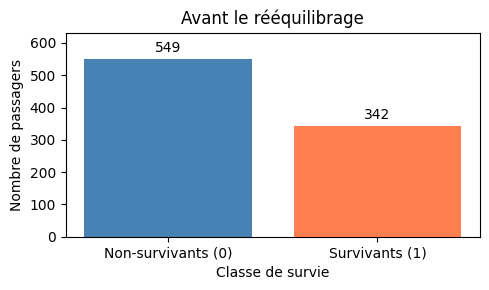

In [5]:
def tracer_repartition(cible, titre):
    effectifs = cible.value_counts().reindex([0, 1], fill_value=0)
    plt.figure(figsize=(5, 3))
    barres = plt.bar(["Non-survivants (0)", "Survivants (1)"],
                     effectifs.values, color=["steelblue", "coral"])
    plt.bar_label(barres, padding=3)
    plt.title(titre)
    plt.xlabel("Classe de survie")
    plt.ylabel("Nombre de passagers")
    plt.ylim(0, effectifs.max() * 1.15)
    plt.tight_layout()
    plt.show()

tracer_repartition(y, "Avant le rééquilibrage")

**Interprétation :** Il y a 549 non-survivants contre 342 survivants. La classe des non-survivants est donc majoritaire.

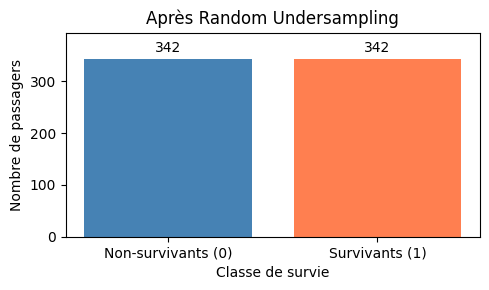

In [6]:
tracer_repartition(y_sous, "Après Random Undersampling")

**Interprétation :** Chaque classe contient 342 passagers. Le sous-échantillonnage a retiré 207 non-survivants.

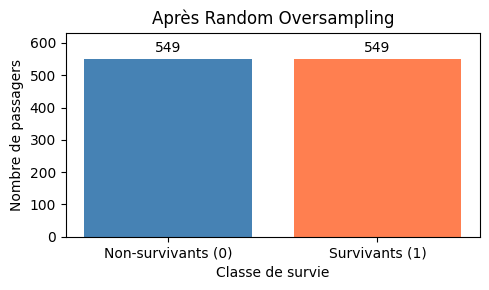

In [7]:
tracer_repartition(y_sur, "Après Random Oversampling")

**Interprétation :** Chaque classe contient 549 passagers. Le suréchantillonnage a ajouté 207 copies de survivants.

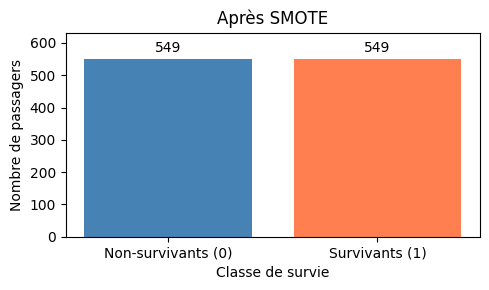

In [8]:
tracer_repartition(y_smote, "Après SMOTE")

**Interprétation :** Chaque classe contient 549 exemples. SMOTE a créé 207 exemples synthétiques de survivants pour équilibrer les classes.